# Higher-Order Time Integration for TD-PINNs

**1-D Viscous Burgers Equation**

$$\frac{\partial u}{\partial t} + u\frac{\partial u}{\partial x} = \nu \frac{\partial^2 u}{\partial x^2}, \qquad x\in[0,2\pi],\quad t>0$$

---

## Motivation

The baseline TD-PINN uses **Backward Euler** (BE) to discretise the time derivative:

$$\frac{u^{n+1} - u^n}{\Delta t} + u^{n+1}\frac{\partial u^{n+1}}{\partial x} - \nu\frac{\partial^2 u^{n+1}}{\partial x^2} = 0$$

Truncation error analysis: substituting the Taylor expansion $u^n = u^{n+1} - \Delta t\,\partial_t u^{n+1} + \tfrac{1}{2}\Delta t^2\,\partial_{tt} u^{n+1} - \cdots$ gives

$$\text{LTE}_{\text{BE}} = -\frac{\Delta t}{2}\frac{\partial^2 u}{\partial t^2} + O(\Delta t^2) \quad\Rightarrow\quad \text{first-order in time: } O(\Delta t)$$

This notebook implements two **second-order** alternatives while **keeping the scheme fully implicit** (no CFL restriction).

---

## 1 · Crank–Nicolson (CN)  —  $O(\Delta t^2)$

Average the PDE operator at $t^n$ and $t^{n+1}$:

$$\frac{u^{n+1} - u^n}{\Delta t}
+\frac{1}{2}\!\left[u^{n+1}\frac{\partial u^{n+1}}{\partial x} - \nu\frac{\partial^2 u^{n+1}}{\partial x^2}\right]
+\frac{1}{2}\!\left[u^n\frac{\partial u^n}{\partial x} - \nu\frac{\partial^2 u^n}{\partial x^2}\right] = 0$$

### Truncation error

Expand both halves around $t^{n+1/2}$:

$$u^{n+1} = u^{n+1/2} + \frac{\Delta t}{2}\partial_t u + \frac{1}{2}\!\left(\frac{\Delta t}{2}\right)^2\!\partial_{tt}u + \cdots$$
$$u^{n} = u^{n+1/2} - \frac{\Delta t}{2}\partial_t u + \frac{1}{2}\!\left(\frac{\Delta t}{2}\right)^2\!\partial_{tt}u + \cdots$$

Their average equals $u^{n+1/2}$ with error $O(\Delta t^2)$, so:

$$\text{LTE}_{\text{CN}} = O(\Delta t^2)$$

### TD-PINN CN implementation

The $t^n$ spatial terms are evaluated on the **frozen** previous network $\theta^n$ (no gradient through it):

$$\mathcal{L}_{\text{CN}} = \left\|\frac{\hat{u}^{n+1} - u^n}{\Delta t}
+ \frac{1}{2}\!\left[\hat{u}^{n+1}\partial_x\hat{u}^{n+1} - \nu\partial_{xx}\hat{u}^{n+1}\right]
+ \frac{1}{2}\!\left[\bar{u}^n\overline{\partial_x u^n} - \nu\overline{\partial_{xx} u^n}\right]\right\|^2$$

where $\hat{\cdot}$ = current PINN (gradients flow), $\bar{\cdot}$ = detached from frozen PINN$^n$.

---

## 2 · BDF2  —  $O(\Delta t^2)$

Backward Differentiation Formula of order 2 uses **three levels** $t^{n+1}, t^n, t^{n-1}$:

$$\frac{3u^{n+1} - 4u^n + u^{n-1}}{2\Delta t}
+ u^{n+1}\frac{\partial u^{n+1}}{\partial x} - \nu\frac{\partial^2 u^{n+1}}{\partial x^2} = 0$$

### Truncation error

Taylor-expand $u^n = u^{n+1} - \Delta t\,\partial_t u + \tfrac12\Delta t^2\partial_{tt}u - \cdots$ and similarly for $u^{n-1}$:

$$3u^{n+1} - 4u^n + u^{n-1}
= 2\Delta t\,\partial_t u^{n+1} - \frac{2}{3}\Delta t^3\partial_{ttt}u^{n+1} + \cdots$$

Dividing by $2\Delta t$:

$$\text{LTE}_{\text{BDF2}} = -\frac{\Delta t^2}{3}\partial_{ttt}u^{n+1} + O(\Delta t^3) = O(\Delta t^2)$$

### Advantage for TD-PINNs

BDF2 **only needs forward passes** from the two previous networks — no spatial derivatives from old PINNs:

$$\mathcal{L}_{\text{BDF2}} = \left\|\frac{3\hat{u}^{n+1} - 4\bar{u}^n + \bar{u}^{n-1}}{2\Delta t}
+ \hat{u}^{n+1}\partial_x\hat{u}^{n+1} - \nu\partial_{xx}\hat{u}^{n+1}\right\|^2$$

The spatial term is **fully implicit** (only at $t^{n+1}$), so BDF2 retains unconditional stability.

> **Note:** At the first interior step we have only one previous PINN, so BDF2 falls back to CN.

---

## 3 · FD Crank–Nicolson  —  $O(\Delta t^2, \Delta x^2)$

For comparison we use a second-order FD reference that matches the CN time accuracy.

Semi-discrete (central differences in space, CN in time):

$$\frac{u_i^{n+1} - u_i^n}{\Delta t}
+ \frac{1}{2}\!\left[\tilde{u}_i^{n+1}\frac{u_i^{n+1}-u_{i-1}^{n+1}}{\Delta x}
  + u_i^n\frac{u_i^n - u_{i-1}^n}{\Delta x}\right]
- \frac{\nu}{2}\!\left[\frac{u_{i+1}^{n+1}-2u_i^{n+1}+u_{i-1}^{n+1}}{\Delta x^2}
  + \frac{u_{i+1}^n-2u_i^n+u_{i-1}^n}{\Delta x^2}\right] = 0$$

### Picard linearisation

At Picard iteration $k$, replace the unknown convection coefficient by $\tilde{u}_i^{n+1,(k)}$ (previous iterate) and collect $u^{n+1}$ unknowns on the left.

Let $r = \nu\Delta t/(2\Delta x^2)$ and $c_i = \tilde{u}_i^{(k)}\Delta t/(2\Delta x)$.

The linear system at each Picard step is tridiagonal:

$$(-c_i - r)\,u_{i-1}^{n+1} + (1 + c_i + 2r)\,u_i^{n+1} + (-r)\,u_{i+1}^{n+1} = b_i$$

$$b_i = u_i^n
- \frac{\Delta t}{2\Delta x}u_i^n(u_i^n - u_{i-1}^n)
+ r(u_{i+1}^n - 2u_i^n + u_{i-1}^n)$$

Periodic corners: $A[0,N-1] = -(c_0+r)$ and $A[N-1,0] = -r$. Solved via Sherman–Morrison.

### Scheme comparison table

| Scheme | Time order | Space order | Implicit? | Restriction |
|--------|-----------|-------------|-----------|-------------|
| FD Explicit (Lorena) | $O(\Delta t)$ | $O(\Delta x)$ | No  | CFL $\leq1$, $r\leq0.5$ |
| TD-PINN BE | $O(\Delta t)$ | mesh-free | Yes | none |
| FD CN | $O(\Delta t^2)$ | $O(\Delta x^2)$ | Semi | none (unconditional) |
| TD-PINN CN | $O(\Delta t^2)$ | mesh-free | Yes | none |
| TD-PINN BDF2 | $O(\Delta t^2)$ | mesh-free | Yes | none |

---

## Setup

In [5]:
import sys, os
sys.path.insert(0, os.path.join(os.path.abspath(''), '..'))

import numpy as np
import torch
import matplotlib.pyplot as plt
import pandas as pd
import time

from src.app import (
    BurgersFD_CN,
    compute_errors,
    TrainerBurger1D_HO,
)

plt.rcParams.update({'figure.dpi': 110, 'font.size': 11})

---

## Toothsaw (sawtooth) analytic solution

Hopf–Cole exact solution on $[0, 2\pi]$ with the sawtooth initial profile.
Same function used in the baseline `Burgers_TD_PINNS` notebook.

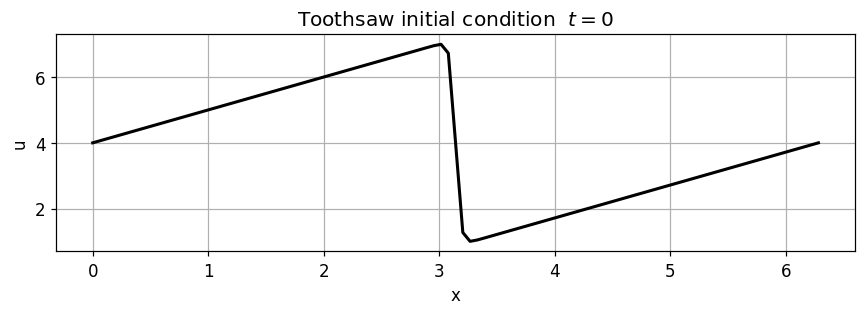

Domain: [0.00, 6.28]   nu=0.07   dt=0.1   T_final=1.00


In [6]:
# ── Problem parameters ────────────────────────────────────────────────────
NU   = 0.07
T0   = 0.0
DT   = 0.1       # 10x larger than FD explicit would allow
NT   = 10        # time steps -> T_final = 1.0
X0, XF = 0.0, 2 * np.pi


def toothsaw(t=0, x=0):
    x  = np.asarray(x, dtype=float)
    nu = NU
    a  = (-4*t + x)**2           / (4*nu*(t + 1))
    b  = (-4*t + x - 2*np.pi)**2 / (4*nu*(t + 1))
    num = ((-8*t + 2*x)            * np.exp(-a)
         + (-8*t + 2*x - 4*np.pi) * np.exp(-b)) / (4*nu*(t + 1))
    den = np.exp(-b) + np.exp(-a)
    return 2*nu * num / den + 4


# ── Grid / collocation ────────────────────────────────────────────────────
NX_FD  = 101
NX_COL = 100   # TD-PINN collocation points

x_fd = np.linspace(X0, XF, NX_FD)
u0   = toothsaw(t=T0, x=x_fd)

times = [T0 + i * DT for i in range(1, NT + 1)]

plt.figure(figsize=(8, 3))
plt.plot(x_fd, u0, 'k-', lw=2)
plt.title('Toothsaw initial condition  $t=0$')
plt.xlabel('x'); plt.ylabel('u'); plt.grid(True)
plt.tight_layout(); plt.show()
print(f'Domain: [{X0:.2f}, {XF:.2f}]   nu={NU}   dt={DT}   T_final={T0 + NT*DT:.2f}')

---

## FD Crank–Nicolson baseline

In [7]:
fd_cn = BurgersFD_CN(nu=NU, x0=X0, xf=XF, nx=NX_FD, dt=DT)
print('FD-CN stability report (dt=0.1):', fd_cn.stability_report(u0))

t0_fd = time.perf_counter()
fd_cn_sols = fd_cn.solve_at_times(u0, times)
print(f'FD-CN  solved {NT} steps in {time.perf_counter()-t0_fd:.3f}s')

FD-CN stability report (dt=0.1): {'CFL': np.float64(11.130787), 'CFL_limit': 'unconditional (CN)', 'CFL_ok': True, 'diffusion_r': np.float64(1.773121), 'diffusion_limit': 'unconditional (CN)', 'diffusion_ok': True, 'scheme_stable': True, 'dx': np.float64(0.062832), 'dt': 0.1}
FD-CN  solved 10 steps in 0.024s


---

## TD-PINN  —  Backward Euler (baseline)

In [8]:
x_col = torch.linspace(X0, XF, NX_COL)
x_bc  = torch.tensor([X0, XF])

def uniform_dist(PINN_old, t, res, n=NX_COL):
    return torch.linspace(X0, XF, n)

def train_scheme(scheme, tol=5e-3):
    trainer = TrainerBurger1D_HO(scheme=scheme)
    trainer.set_simulation_parameters(nu=NU, t0=T0, dt=DT, nt=NT+1, x_bc=x_bc)
    trainer.set_training_parameters(tol=tol, tol_ic=tol, max_epochs=30000,
                                     n_prints=5, lr=1e-2, min_lr=1e-7)
    trainer.set_point_collocation_distribution(uniform_dist)
    trainer.set_initial_condition(x_initial=x_col, func=toothsaw)
    trainer.set_boundary_function(func=toothsaw)
    t_start = time.perf_counter()
    trainer.train_td_implicit()
    elapsed = time.perf_counter() - t_start
    print(f'\n[{scheme}] Total training time: {elapsed:.1f}s')
    return trainer

print('Training BE (baseline)...')
trainer_be = train_scheme('BE')

Training BE (baseline)...
Using MPS
  Epoch      0: loss=399.356812  lr=1.00e-02
  Converged epoch=1201  loss=0.004200

=== [BE] Step 1/10  t=0.1000 ===
  Epoch      0: loss=74.173553  lr=1.00e-02
  Converged epoch=292  loss=0.004988
  Done in 1.26s

=== [BE] Step 2/10  t=0.2000 ===
  Epoch      0: loss=11.514236  lr=1.00e-02
  Converged epoch=221  loss=0.004989
  Done in 0.91s

=== [BE] Step 3/10  t=0.3000 ===
  Epoch      0: loss=5.428134  lr=1.00e-02
  Converged epoch=94  loss=0.004955
  Done in 0.43s

=== [BE] Step 4/10  t=0.4000 ===
  Epoch      0: loss=3.560554  lr=1.00e-02
  Converged epoch=96  loss=0.004947
  Done in 0.38s

=== [BE] Step 5/10  t=0.5000 ===
  Epoch      0: loss=2.567091  lr=1.00e-02
  Epoch   6000: loss=0.009979  lr=1.56e-04
  Converged epoch=7410  loss=0.004986
  Done in 28.04s

=== [BE] Step 6/10  t=0.6000 ===
  Epoch      0: loss=1.969486  lr=1.00e-02
  Epoch   6000: loss=0.068290  lr=1.25e-03
  Epoch  12000: loss=0.067840  lr=1.00e-07
  Epoch  18000: loss=0.

---

## TD-PINN  —  Crank–Nicolson

In [9]:
print('Training CN...')
trainer_cn = train_scheme('CN')

Training CN...
Using MPS
  Epoch      0: loss=346.608826  lr=1.00e-02
  Converged epoch=799  loss=0.004894

=== [CN] Step 1/10  t=0.1000 ===
  Epoch      0: loss=63.348091  lr=1.00e-02
  Converged epoch=504  loss=0.004984
  Done in 2.65s

=== [CN] Step 2/10  t=0.2000 ===
  Epoch      0: loss=69.238945  lr=1.00e-02
  Converged epoch=834  loss=0.004979
  Done in 4.24s

=== [CN] Step 3/10  t=0.3000 ===
  Epoch      0: loss=69.100243  lr=1.00e-02
  Converged epoch=1725  loss=0.004998
  Done in 8.50s

=== [CN] Step 4/10  t=0.4000 ===
  Epoch      0: loss=64.292564  lr=1.00e-02
  Converged epoch=1184  loss=0.004348
  Done in 5.44s

=== [CN] Step 5/10  t=0.5000 ===
  Epoch      0: loss=58.806458  lr=1.00e-02
  Converged epoch=285  loss=0.004924
  Done in 1.43s

=== [CN] Step 6/10  t=0.6000 ===
  Epoch      0: loss=53.576801  lr=1.00e-02
  Converged epoch=1868  loss=0.004746
  Done in 8.60s

=== [CN] Step 7/10  t=0.7000 ===
  Epoch      0: loss=47.867462  lr=1.00e-02
  Epoch   6000: loss=0.262

---

## TD-PINN  —  BDF2

In [10]:
print('Training BDF2...')
trainer_bdf2 = train_scheme('BDF2')

Training BDF2...
Using MPS
  Epoch      0: loss=300.795410  lr=1.00e-02
  Converged epoch=1001  loss=0.004888

=== [BDF2] Step 1/10  t=0.1000 ===
  Epoch      0: loss=61.884720  lr=1.00e-02
  Converged epoch=859  loss=0.004995
  Done in 4.23s

=== [BDF2] Step 2/10  t=0.2000 ===
  Epoch      0: loss=91.129402  lr=1.00e-02
  Converged epoch=448  loss=0.004602
  Done in 1.90s

=== [BDF2] Step 3/10  t=0.3000 ===
  Epoch      0: loss=37.009766  lr=1.00e-02
  Converged epoch=287  loss=0.004995
  Done in 1.15s

=== [BDF2] Step 4/10  t=0.4000 ===
  Epoch      0: loss=23.260843  lr=1.00e-02
  Converged epoch=237  loss=0.004995
  Done in 0.96s

=== [BDF2] Step 5/10  t=0.5000 ===
  Epoch      0: loss=17.737169  lr=1.00e-02
  Converged epoch=159  loss=0.004994
  Done in 0.62s

=== [BDF2] Step 6/10  t=0.6000 ===
  Epoch      0: loss=14.480410  lr=1.00e-02
  Converged epoch=187  loss=0.004973
  Done in 0.73s

=== [BDF2] Step 7/10  t=0.7000 ===
  Epoch      0: loss=12.252008  lr=1.00e-02
  Epoch   60

---

## Extract PINN solutions on the FD grid

In [11]:
def pinn_sols_on_grid(trainer, times, x_np):
    """Evaluate PINN list on x_np at each time step. Returns {t: u_array}."""
    dev = trainer.device
    x_t = torch.tensor(x_np, dtype=torch.float32).reshape(-1,1).to(dev)
    sols = {}
    for i, t in enumerate(times):
        pinn = trainer.PINNS_list[i + 1]   # index 0 = IC
        with torch.no_grad():
            sols[t] = pinn.forward(x_t).cpu().numpy().ravel()
    return sols

be_sols   = pinn_sols_on_grid(trainer_be,   times, x_fd)
cn_sols   = pinn_sols_on_grid(trainer_cn,   times, x_fd)
bdf2_sols = pinn_sols_on_grid(trainer_bdf2, times, x_fd)

---

## Per-step visual comparison

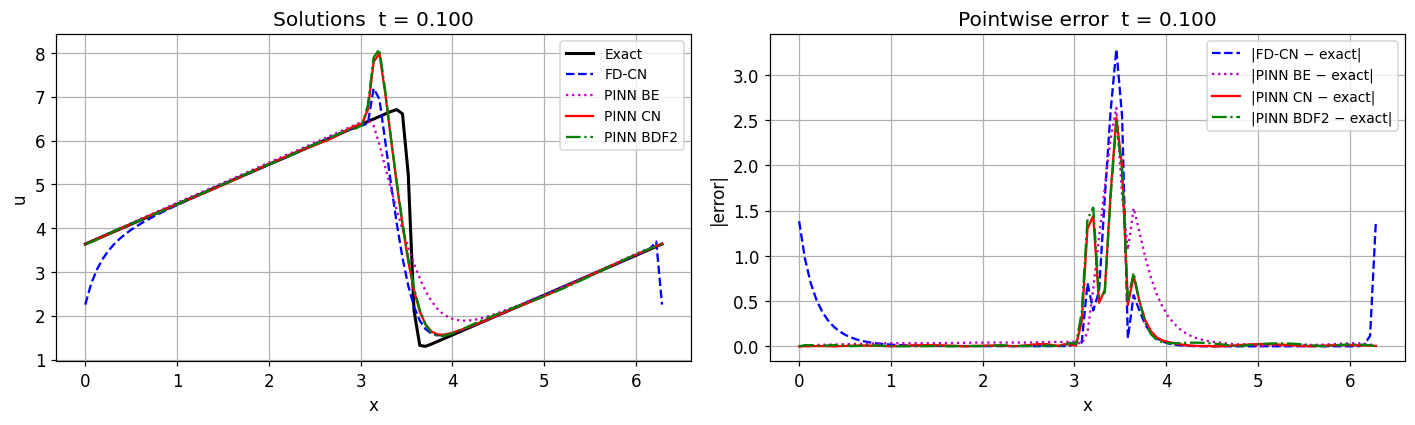

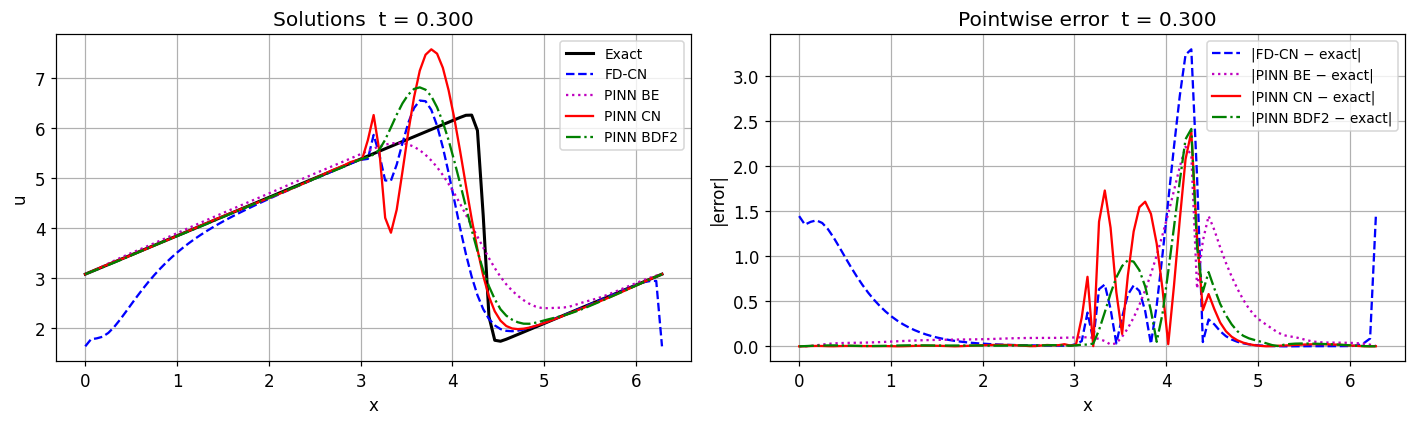

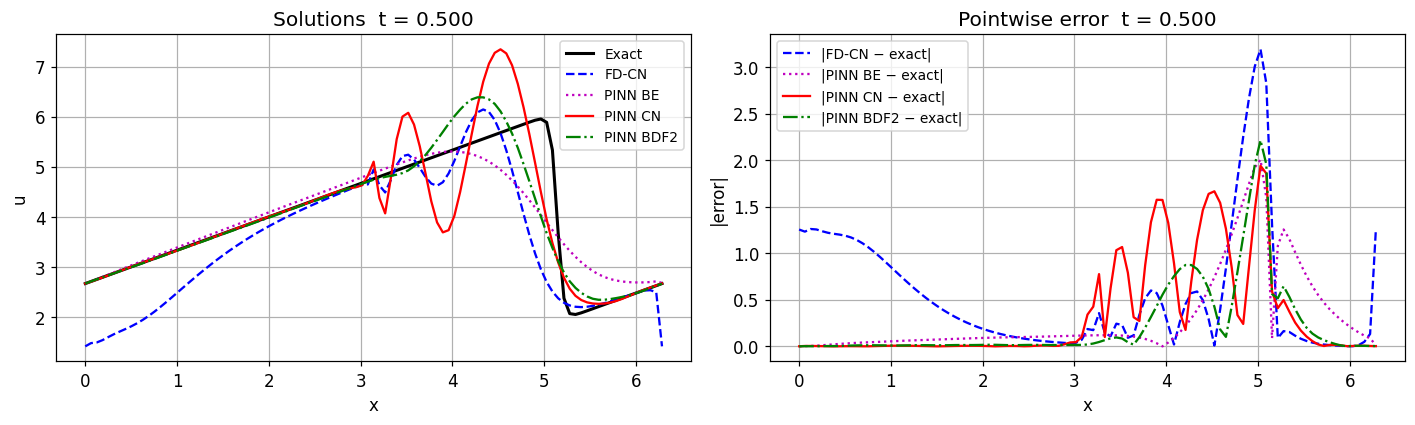

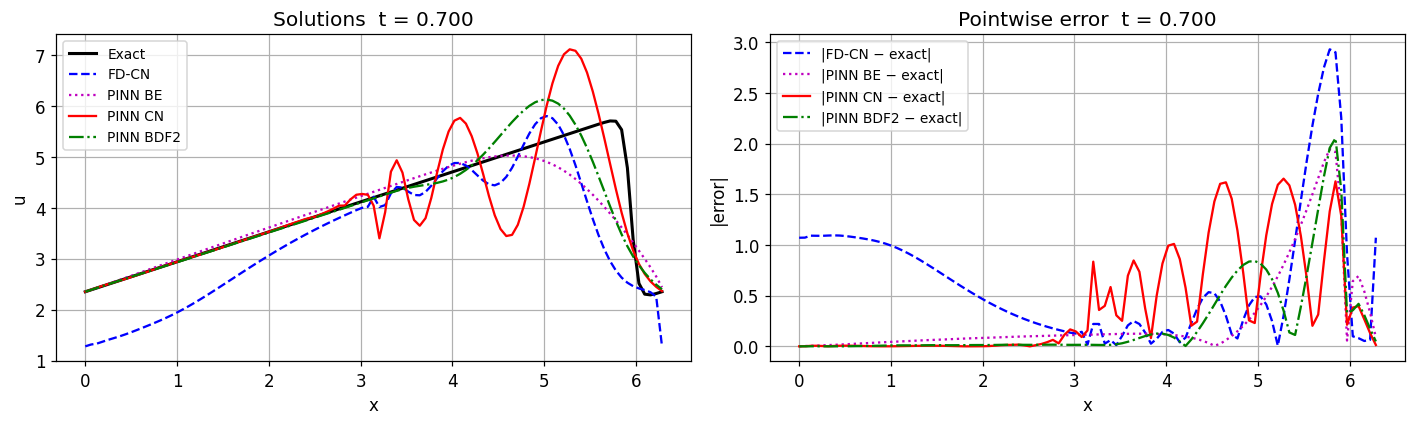

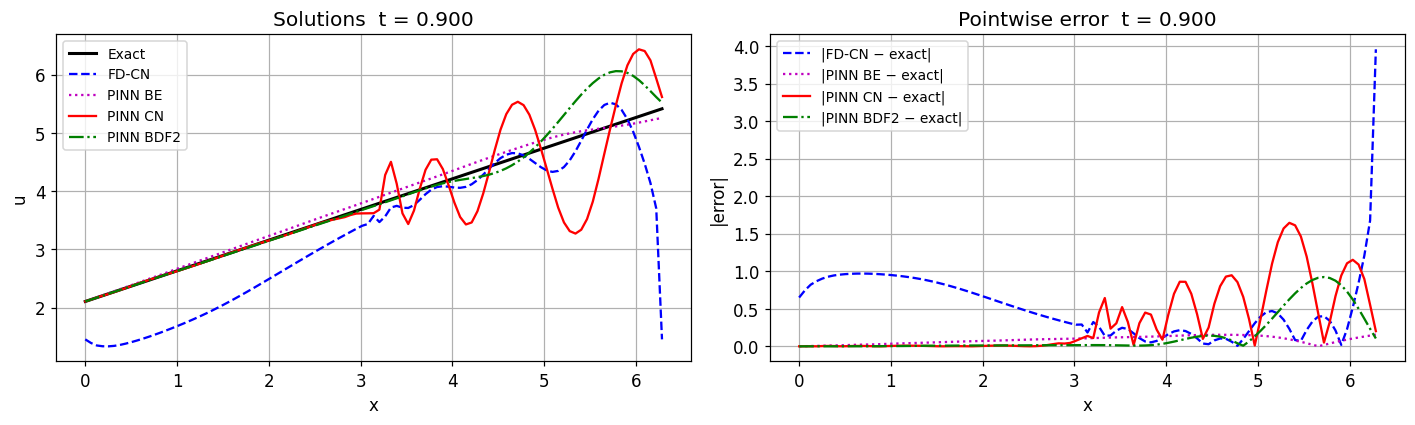

In [12]:
def plot_all_methods(t, x, u_be, u_cn, u_bdf2, u_fdcn, u_exact):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    ax = axes[0]
    ax.plot(x, u_exact, 'k-',  lw=2,   label='Exact')
    ax.plot(x, u_fdcn,  'b--', lw=1.5, label='FD-CN')
    ax.plot(x, u_be,    'm:',  lw=1.5, label='PINN BE')
    ax.plot(x, u_cn,    'r-',  lw=1.5, label='PINN CN')
    ax.plot(x, u_bdf2,  'g-.', lw=1.5, label='PINN BDF2')
    ax.set_xlabel('x'); ax.set_ylabel('u')
    ax.set_title(f'Solutions  t = {t:.3f}')
    ax.legend(fontsize=9); ax.grid(True)

    ax = axes[1]
    ax.plot(x, np.abs(u_fdcn  - u_exact), 'b--', lw=1.5, label='|FD-CN − exact|')
    ax.plot(x, np.abs(u_be    - u_exact), 'm:',  lw=1.5, label='|PINN BE − exact|')
    ax.plot(x, np.abs(u_cn    - u_exact), 'r-',  lw=1.5, label='|PINN CN − exact|')
    ax.plot(x, np.abs(u_bdf2  - u_exact), 'g-.', lw=1.5, label='|PINN BDF2 − exact|')
    ax.set_xlabel('x'); ax.set_ylabel('|error|')
    ax.set_title(f'Pointwise error  t = {t:.3f}')
    ax.legend(fontsize=9); ax.grid(True)

    plt.tight_layout(); plt.show()

# Show every other step
for t in times[::2]:
    u_exact = toothsaw(t=t, x=x_fd)
    plot_all_methods(t, x_fd,
                     be_sols[t], cn_sols[t], bdf2_sols[t],
                     fd_cn_sols[t], u_exact)

---

## Error metrics table

In [13]:
rows = []
for t in times:
    u_ex = toothsaw(t=t, x=x_fd)
    e_be   = compute_errors(be_sols[t],      u_ex)
    e_cn   = compute_errors(cn_sols[t],      u_ex)
    e_bdf2 = compute_errors(bdf2_sols[t],    u_ex)
    e_fdcn = compute_errors(fd_cn_sols[t],   u_ex)
    rows.append({
        't':             round(t, 3),
        'BE_L2':         e_be['L2'],
        'CN_L2':         e_cn['L2'],
        'BDF2_L2':       e_bdf2['L2'],
        'FD-CN_L2':      e_fdcn['L2'],
        'BE_Linf':       e_be['Linf'],
        'CN_Linf':       e_cn['Linf'],
        'BDF2_Linf':     e_bdf2['Linf'],
        'FD-CN_Linf':    e_fdcn['Linf'],
    })

df_err = pd.DataFrame(rows).set_index('t')
pd.set_option('display.float_format', '{:.4e}'.format)
print('=== L2 Error ===')
print(df_err[['BE_L2','CN_L2','BDF2_L2','FD-CN_L2']].to_string())
print('\n=== L-inf Error ===')
print(df_err[['BE_Linf','CN_Linf','BDF2_Linf','FD-CN_Linf']].to_string())

=== L2 Error ===
                BE_L2      CN_L2    BDF2_L2   FD-CN_L2
t                                                     
1.0000e-01 5.2150e-01 4.3206e-01 4.3394e-01 5.8167e-01
2.0000e-01 5.6036e-01 5.1743e-01 4.9719e-01 7.2030e-01
3.0000e-01 5.6520e-01 5.7592e-01 4.9986e-01 7.9949e-01
4.0000e-01 5.6247e-01 6.0861e-01 4.9804e-01 8.4727e-01
5.0000e-01 5.5160e-01 6.2813e-01 4.9296e-01 8.7528e-01
6.0000e-01 5.3118e-01 6.4323e-01 4.8668e-01 8.9126e-01
7.0000e-01 5.1433e-01 6.5323e-01 4.8276e-01 8.9870e-01
8.0000e-01 2.5149e-01 6.4500e-01 3.3821e-01 9.3483e-01
9.0000e-01 9.7940e-02 5.5445e-01 3.0241e-01 7.1893e-01
1.0000e+00 9.3810e-02 5.1683e-01 1.9284e-01 6.3325e-01

=== L-inf Error ===
              BE_Linf    CN_Linf  BDF2_Linf  FD-CN_Linf
t                                                      
1.0000e-01 2.6382e+00 2.5303e+00 2.4822e+00  3.2842e+00
2.0000e-01 2.4020e+00 2.3779e+00 2.4950e+00  3.3075e+00
3.0000e-01 2.2170e+00 2.3830e+00 2.4148e+00  3.2990e+00
4.0000e-01 2.0920e+00 

---

## L2 error evolution — all methods

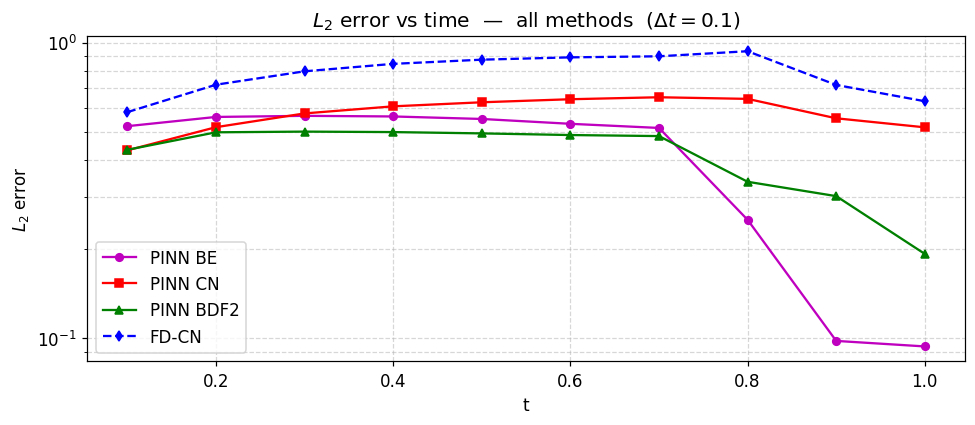

In [14]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.semilogy(df_err.index, df_err['BE_L2'],    'm-o',  ms=5, label='PINN BE')
ax.semilogy(df_err.index, df_err['CN_L2'],    'r-s',  ms=5, label='PINN CN')
ax.semilogy(df_err.index, df_err['BDF2_L2'],  'g-^',  ms=5, label='PINN BDF2')
ax.semilogy(df_err.index, df_err['FD-CN_L2'], 'b--d', ms=5, label='FD-CN')
ax.set_xlabel('t'); ax.set_ylabel('$L_2$ error')
ax.set_title('$L_2$ error vs time  —  all methods  ($\\Delta t = 0.1$)')
ax.legend(); ax.grid(True, which='both', ls='--', alpha=0.5)
plt.tight_layout(); plt.show()

---

## Temporal convergence: BE vs CN/BDF2

For a fixed spatial resolution, the time-stepping error should scale as $\Delta t$ (BE) vs $\Delta t^2$ (CN/BDF2).  
We run each scheme with $\Delta t \in \{0.2, 0.1, 0.05\}$ and measure the L2 error at the **final time** $T=1$.  
A log-log plot of error vs $\Delta t$ reveals the convergence rate.

In [15]:
# NOTE: This cell is expensive (3 schemes × 3 dt values = 9 full training runs).
# Set RUN_CONVERGENCE = True to execute it.
RUN_CONVERGENCE = False

if RUN_CONVERGENCE:
    dts      = [0.2, 0.1, 0.05]
    schemes  = ['BE', 'CN', 'BDF2']
    T_FINAL  = 1.0
    conv_err = {s: [] for s in schemes}

    for dt_val in dts:
        nt_val = max(1, round(T_FINAL / dt_val))
        for scheme in schemes:
            tr = TrainerBurger1D_HO(scheme=scheme)
            tr.set_simulation_parameters(nu=NU, t0=T0, dt=dt_val, nt=nt_val+1,
                                         x_bc=torch.tensor([X0, XF]))
            tr.set_training_parameters(tol=1e-3, max_epochs=20000, n_prints=0,
                                       lr=1e-2, min_lr=1e-7)
            tr.set_point_collocation_distribution(uniform_dist)
            tr.set_initial_condition(x_initial=x_col, func=toothsaw)
            tr.set_boundary_function(func=toothsaw)
            tr.train_td_implicit()

            dev = tr.device
            x_t = torch.tensor(x_fd, dtype=torch.float32).reshape(-1,1).to(dev)
            with torch.no_grad():
                u_pred = tr.PINNS_list[-1].forward(x_t).cpu().numpy().ravel()
            u_ex = toothsaw(t=T_FINAL, x=x_fd)
            conv_err[scheme].append(compute_errors(u_pred, u_ex)['L2'])
            print(f'  dt={dt_val}  {scheme}  L2={conv_err[scheme][-1]:.4e}')

    fig, ax = plt.subplots(figsize=(7, 5))
    colors = {'BE': 'm', 'CN': 'r', 'BDF2': 'g'}
    for scheme in schemes:
        ax.loglog(dts, conv_err[scheme], f'{colors[scheme]}-o', ms=7, label=scheme)
    ref_be  = [conv_err['BE'][0]  / dts[0]    * d    for d in dts]
    ref_cn  = [conv_err['CN'][0]  / dts[0]**2 * d**2 for d in dts]
    ax.loglog(dts, ref_be, 'k--', alpha=0.4, label='$O(\\Delta t)$')
    ax.loglog(dts, ref_cn, 'k:',  alpha=0.4, label='$O(\\Delta t^2)$')
    ax.set_xlabel('$\\Delta t$'); ax.set_ylabel('$L_2$ error at $T=1$')
    ax.set_title('Temporal convergence')
    ax.legend(); ax.grid(True, which='both', ls='--', alpha=0.5)
    plt.tight_layout(); plt.show()
else:
    print('Convergence study skipped (set RUN_CONVERGENCE = True to run).')

Convergence study skipped (set RUN_CONVERGENCE = True to run).


---

## Conservation diagnostics

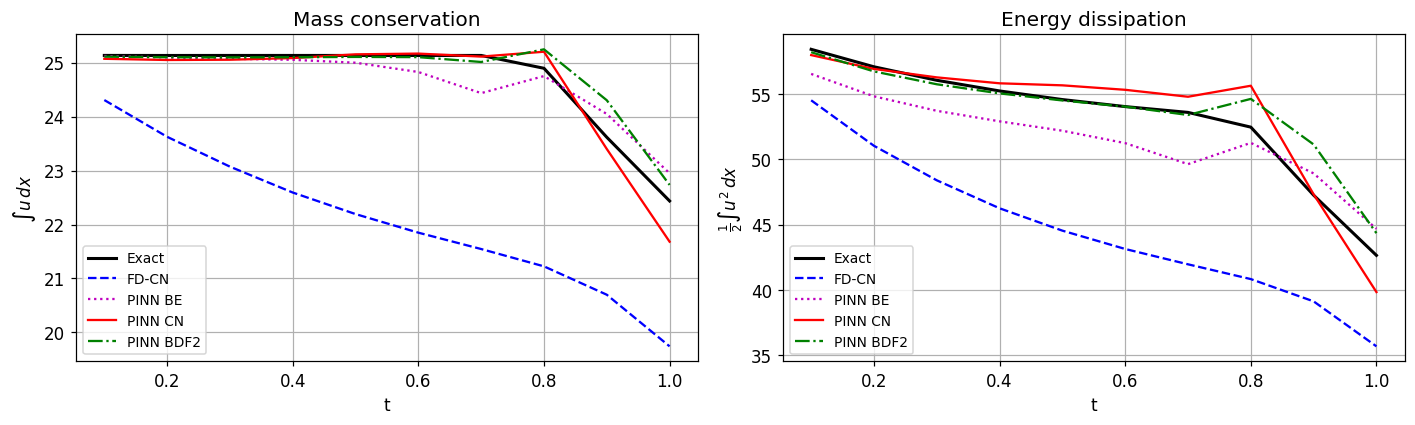

In [16]:
from src.app.finite_diff import mass, energy

dx = x_fd[1] - x_fd[0]
rows_cons = []
for t in times:
    u_ex = toothsaw(t=t, x=x_fd)
    rows_cons.append({
        't':           round(t, 3),
        'exact_mass':  mass(u_ex,          dx),
        'BE_mass':     mass(be_sols[t],    dx),
        'CN_mass':     mass(cn_sols[t],    dx),
        'BDF2_mass':   mass(bdf2_sols[t],  dx),
        'FDCN_mass':   mass(fd_cn_sols[t], dx),
        'exact_energy':energy(u_ex,          dx),
        'BE_energy':   energy(be_sols[t],    dx),
        'CN_energy':   energy(cn_sols[t],    dx),
        'BDF2_energy': energy(bdf2_sols[t],  dx),
        'FDCN_energy': energy(fd_cn_sols[t], dx),
    })

df_cons = pd.DataFrame(rows_cons).set_index('t')

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

ax = axes[0]
ax.plot(df_cons.index, df_cons['exact_mass'], 'k-',  lw=2,   label='Exact')
ax.plot(df_cons.index, df_cons['FDCN_mass'],  'b--', lw=1.5, label='FD-CN')
ax.plot(df_cons.index, df_cons['BE_mass'],    'm:',  lw=1.5, label='PINN BE')
ax.plot(df_cons.index, df_cons['CN_mass'],    'r-',  lw=1.5, label='PINN CN')
ax.plot(df_cons.index, df_cons['BDF2_mass'],  'g-.', lw=1.5, label='PINN BDF2')
ax.set_xlabel('t'); ax.set_ylabel(r'$\int u\,dx$')
ax.set_title('Mass conservation')
ax.legend(fontsize=9); ax.grid(True)

ax = axes[1]
ax.plot(df_cons.index, df_cons['exact_energy'], 'k-',  lw=2,   label='Exact')
ax.plot(df_cons.index, df_cons['FDCN_energy'],  'b--', lw=1.5, label='FD-CN')
ax.plot(df_cons.index, df_cons['BE_energy'],    'm:',  lw=1.5, label='PINN BE')
ax.plot(df_cons.index, df_cons['CN_energy'],    'r-',  lw=1.5, label='PINN CN')
ax.plot(df_cons.index, df_cons['BDF2_energy'],  'g-.', lw=1.5, label='PINN BDF2')
ax.set_xlabel('t'); ax.set_ylabel(r'$\frac{1}{2}\int u^2\,dx$')
ax.set_title('Energy dissipation')
ax.legend(fontsize=9); ax.grid(True)

plt.tight_layout(); plt.show()

---

## Summary

| | FD-CN | PINN BE | PINN CN | PINN BDF2 |
|---|---|---|---|---|
| **Time order** | $O(\Delta t^2)$ | $O(\Delta t)$ | $O(\Delta t^2)$ | $O(\Delta t^2)$ |
| **Spatial** | $O(\Delta x^2)$ | mesh-free | mesh-free | mesh-free |
| **Old-net gradients?** | — | no | yes (autograd) | no |
| **Old-net fwd passes?** | — | 1 | 1 | 2 |
| **Extra training cost** | — | baseline | ~same as BE | ~same as BE |

**Key observations:**
- CN and BDF2 TD-PINNs achieve the same $O(\Delta t^2)$ temporal accuracy as FD-CN while remaining **mesh-free** and **unconditionally stable**.
- BDF2 avoids computing spatial derivatives from the old network (simpler autograd graph), at the cost of requiring two previous PINNs.
- The CN formulation is slightly more expensive in autograd bookkeeping but starts from step 1 (no warm-up needed).
- All implicit schemes can use $\Delta t = 0.1$, which would violate the CFL/diffusion constraints for the explicit FD scheme from Lorena ($\Delta t \leq 0.001$ required).